# 2. Model

This notebook applies all described methods on the cleaned dataset

## Loading packages and preprocessed datasets

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import minimize
from tqdm import tqdm
from sklearn.model_selection import KFold
from sklearn.metrics import brier_score_loss
from sklearn.calibration import calibration_curve
from datetime import timedelta
import json
import ast
import matplotlib.dates as mdates
import matplotlib.colors as mcolors
from matplotlib.cm import ScalarMappable
from matplotlib.colors import ListedColormap

# Make sure that all columns are visible when a dataframe is printed
pd.set_option('display.max_columns', None)
# Reusable model calculations and plotting helpers
from src.model import (
    bootstrap_confidence_intervals_pred, cross_validation_adaptive_window_pos,
    cross_validation_adaptive_window_simple, log_likelihood,
    log_likelihood_simple_weighted, predict_postest,
    risk_mle_adaptive_triangle_only_pos,
)
from src.plotting import (
    plot_cause_split, plot_cause_split_proportions, risk_plot,
    smoothed_predictions_plot, smoothed_predictions_plot_CI,
)


In [2]:
# Load different datasets
df_max0 = pd.read_csv("data/all_cleaned_instances_0.csv")
df_max1 = pd.read_csv("data/all_cleaned_instances_1.csv")
df_max2 = pd.read_csv("data/all_cleaned_instances_2.csv")
df_max3 = pd.read_csv("data/all_cleaned_instances_3.csv")
df_max4 = pd.read_csv("data/all_cleaned_instances_4.csv")

## Grid search to determine hyperparameters

(threshold for the maximum number of missing surveys during the baseline period and the size of the sliding window)

In [ ]:
results = []

# Add the datasets to the dictionary
datasets = {
    #"df_max0": df_max0,
    #"df_max1": df_max1,
    "df_max2": df_max2_50neg,
    #"df_max3": df_max3,
    #"df_max4": df_max4
}

# Define the window sizes you want to evaluate
window_sizes = [15, 20, 25, 30, 35]

# Run cross-validation for each combination
for name, df in datasets.items():
    for window_size in window_sizes:
        print(f"\nRunning for dataset: {name}, min_total_tests: {window_size}")
        
        nr_predictions, actuals, predictions, ace, brier, frac_pos, mean_pred, actual_bins, window_sizes_used, max_window_used, pos_tests_used = cross_validation_adaptive_window_pos(df.copy(), window_size, max_window_size_days=63)
        
        results.append({
            "dataset": name,
            "window_size": window_size,
            "ACE": ace,
            "BrierScore": brier,
            "n_samples": len(actuals),
            "fraction_of_positives": json.dumps(frac_pos.tolist()),
            "mean_predicted_values": json.dumps(mean_pred.tolist()),
            "n_predictions": nr_predictions,
            "n_bins": actual_bins,
            "predictions": json.dumps(predictions.tolist()),
            "actuals": json.dumps(actuals.tolist()),
            "window_sizes": json.dumps(window_sizes_used.tolist()),
            "max_window_used": json.dumps(max_window_used.tolist()),
            "pos_tests_used": json.dumps(pos_tests_used.tolist())
        })

# Convert results to DataFrame
results_df = pd.DataFrame(results)
results_df.to_csv("crossval_data/crossval_summary_adaptive_pos_2_x_63.csv", index=False)


Running for dataset: df_max2, min_total_tests: 15
Processing Fold 1
Processing Fold 2
Processing Fold 3
Processing Fold 4
Processing Fold 5
Processing Fold 6
Processing Fold 7
Processing Fold 8
Processing Fold 9
Processing Fold 10

Running for dataset: df_max2, min_total_tests: 20
Processing Fold 1
Processing Fold 2
Processing Fold 3
Processing Fold 4
Processing Fold 5
Processing Fold 6
Processing Fold 7
Processing Fold 8
Processing Fold 9
Processing Fold 10

Running for dataset: df_max2, min_total_tests: 25
Processing Fold 1
Processing Fold 2
Processing Fold 3
Processing Fold 4
Processing Fold 5
Processing Fold 6
Processing Fold 7
Processing Fold 8
Processing Fold 9
Processing Fold 10

Running for dataset: df_max2, min_total_tests: 30
Processing Fold 1
Processing Fold 2
Processing Fold 3
Processing Fold 4
Processing Fold 5
Processing Fold 6
Processing Fold 7
Processing Fold 8
Processing Fold 9
Processing Fold 10

Running for dataset: df_max2, min_total_tests: 35
Processing Fold 1
Pro

In [3]:
df_0 = pd.read_csv("crossval_data/crossval_summary_adaptive_pos_0_x_63.csv")
df_1 = pd.read_csv("crossval_data/crossval_summary_adaptive_pos_1_x_63.csv")
df_2 = pd.read_csv("crossval_data/crossval_summary_adaptive_pos_2_x_63.csv")
df_3 = pd.read_csv("crossval_data/crossval_summary_adaptive_pos_3_x_63.csv")
df_4 = pd.read_csv("crossval_data/crossval_summary_adaptive_pos_4_x_63.csv")

df_crossval_results = pd.concat([df_0, df_1, df_2, df_3, df_4], ignore_index=True)
# Convert string to list in each row
df_crossval_results["window_sizes"] = df_crossval_results["window_sizes"].apply(ast.literal_eval)

# Compute average window size per row
df_crossval_results["avg_window_size"] = df_crossval_results["window_sizes"].apply(lambda x: sum(x) / len(x))
#df_crossval_results

Plot the results

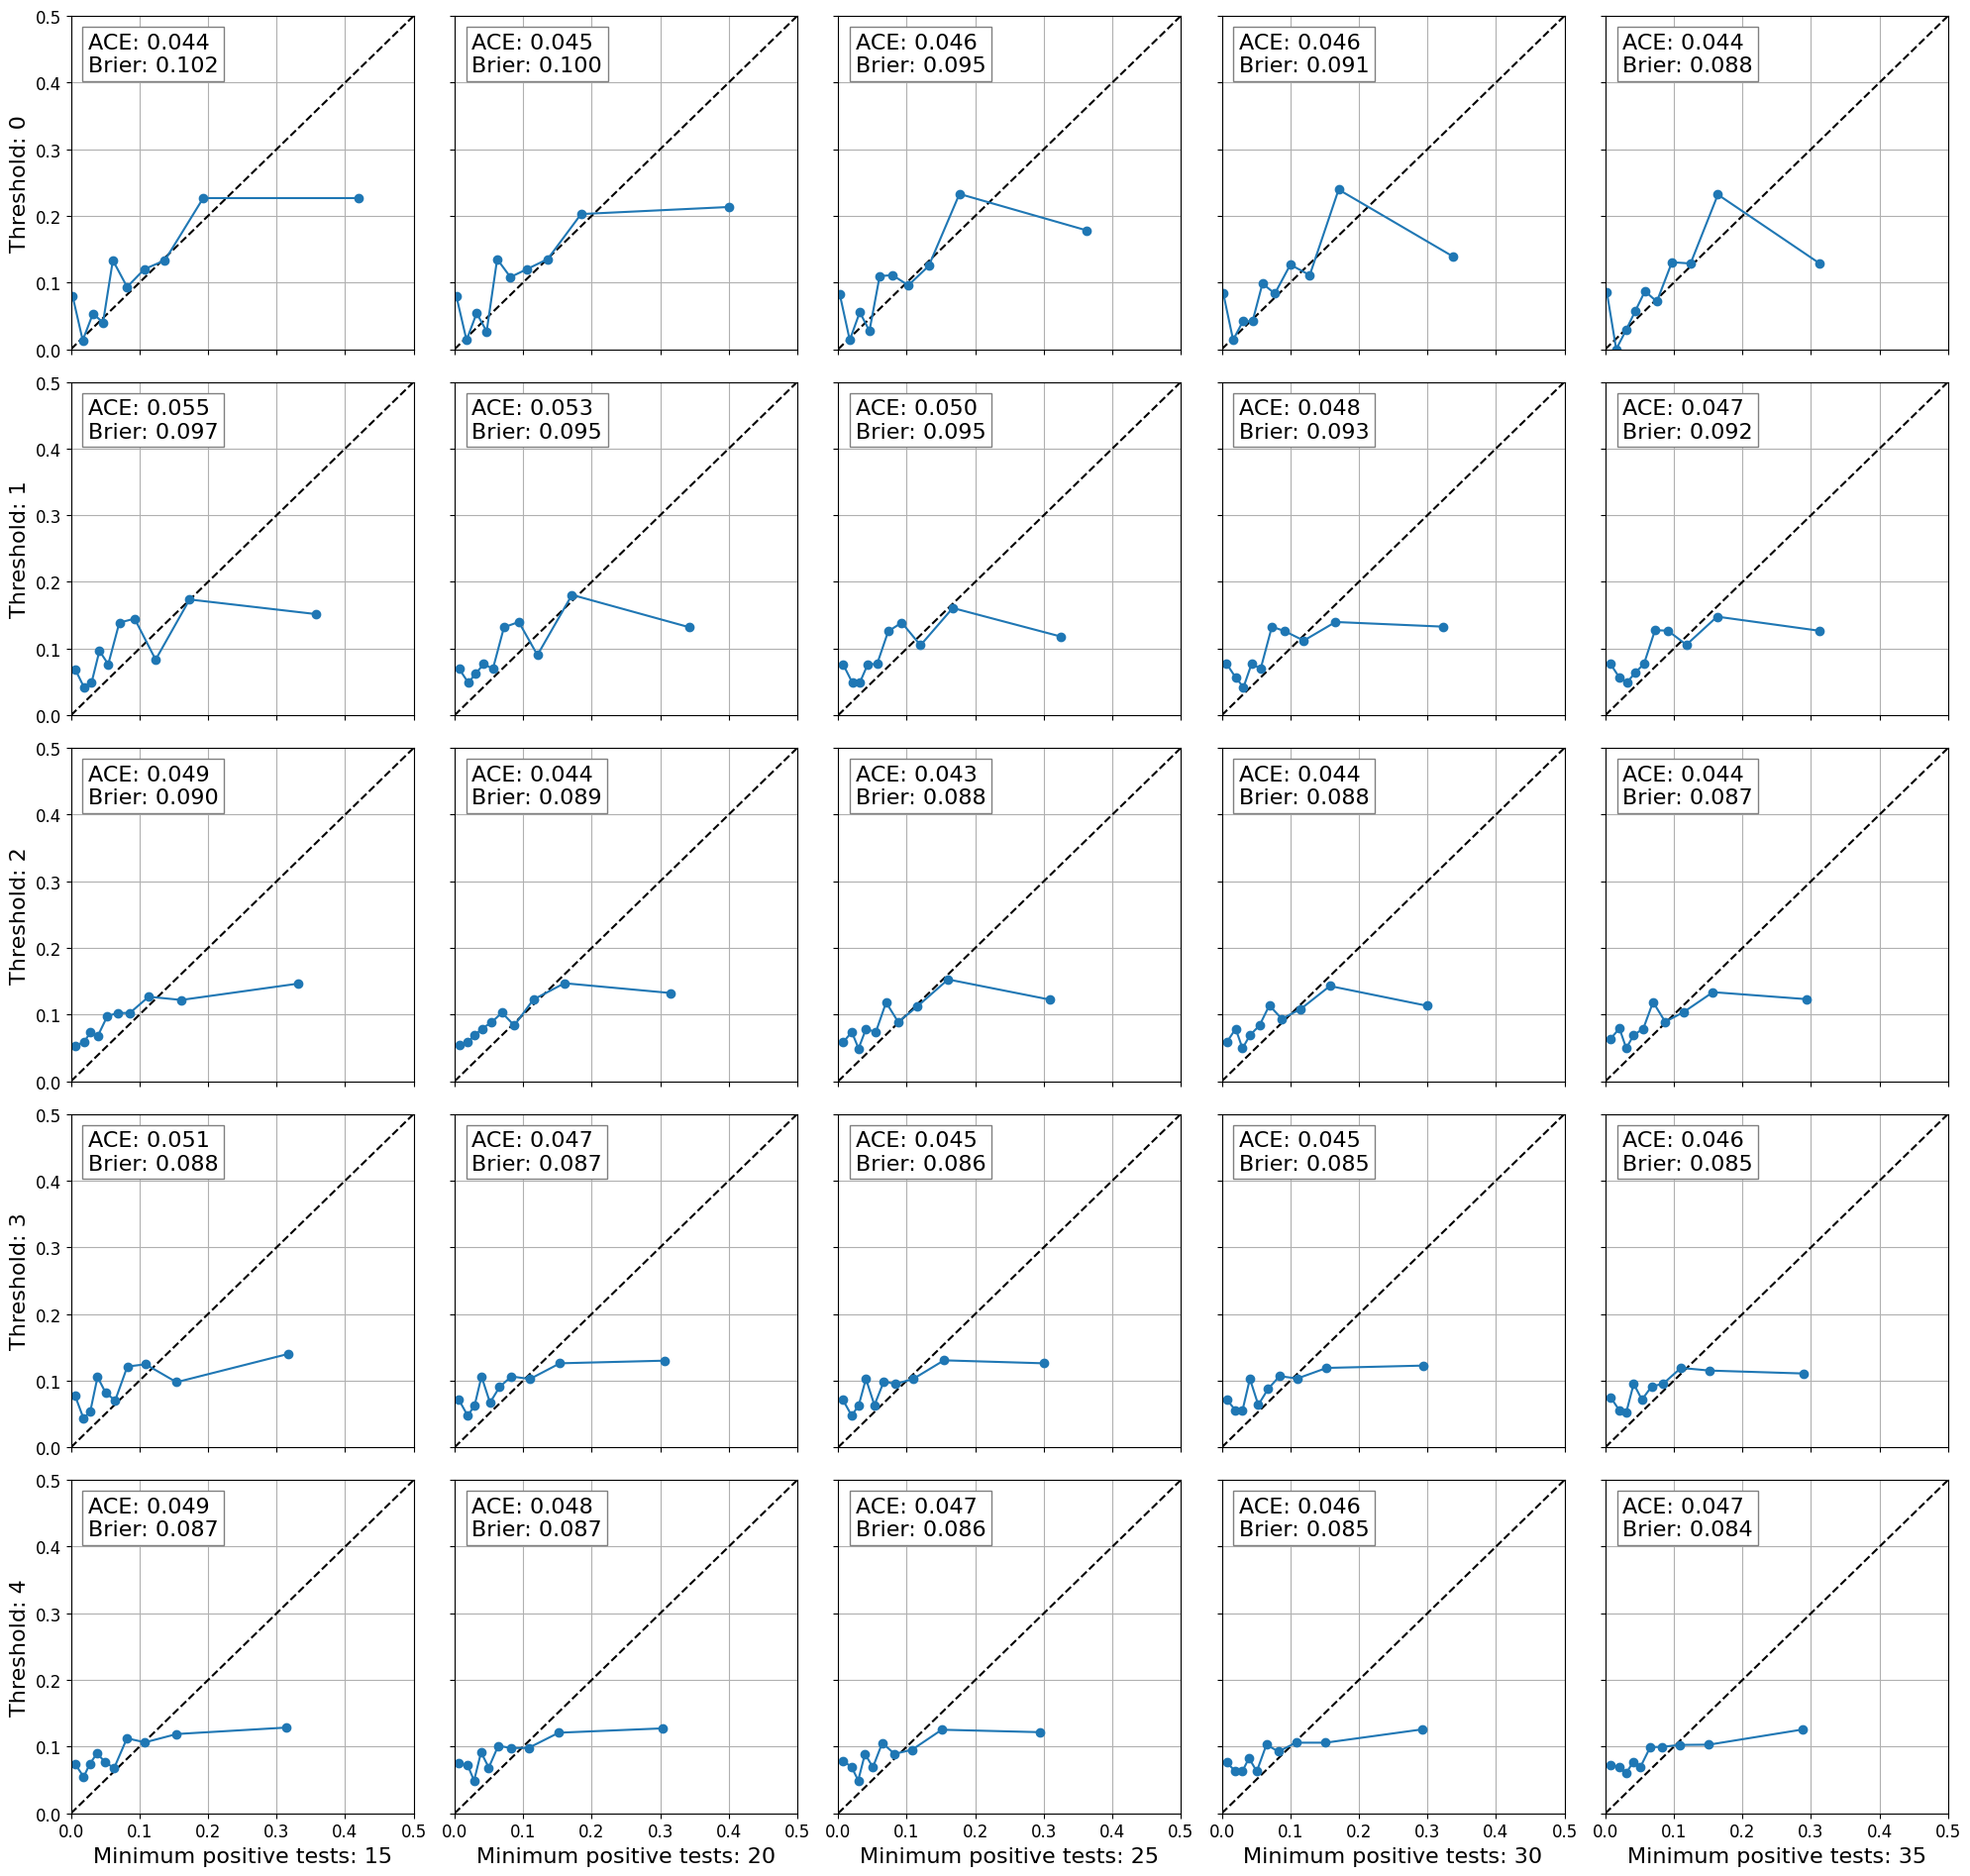

In [ ]:
datasets = sorted(df_crossval_results["dataset"].unique())
window_sizes = sorted(df_crossval_results["window_size"].unique())

n_rows = len(datasets)
n_cols = len(window_sizes)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 4 * n_rows), sharex=True, sharey=True)

for i, dataset in enumerate(datasets):
    for j, window_size in enumerate(window_sizes):
        ax = axes[i, j] if n_rows > 1 else axes[j]

        # Filter the corresponding row in df_crossval_results
        row = df_crossval_results[(df_crossval_results["dataset"] == dataset) & (df_crossval_results["window_size"] == window_size)]

        if row.empty:
            ax.axis('off')  # Hide axes if data missing
            continue

        mean_pred = np.array(json.loads(row.iloc[0]["mean_predicted_values"]))
        frac_pos = np.array(json.loads(row.iloc[0]["fraction_of_positives"]))
        ace = row.iloc[0]["ACE"]
        brier = row.iloc[0]["BrierScore"]
        avg_window_size = round(row.iloc[0]["avg_window_size"], 1)

        # Plot calibration curve and reference line
        ax.plot([0, 1], [0, 1], "--", label="Perfect calibration", color="black")
        ax.plot(mean_pred, frac_pos, "o-", label="Model", color="tab:blue")

        # Add annotations for ACE and Brier Score
        ax.text(0.05, 0.95, f"ACE: {ace:.3f}\nBrier: {brier:.3f}",
                transform=ax.transAxes, fontsize=16,
                verticalalignment='top', bbox=dict(facecolor='white', alpha=1, edgecolor='gray'))

        # Label x-axis only for bottom row, y-axis only for first column
        if i == n_rows - 1:
            ax.set_xlabel(f"Minimum positive tests: {window_size}", fontsize=16)
        if j == 0:
            ax.set_ylabel(f"Threshold: {dataset[-1]}", fontsize=16)

        # Only show legend on the first subplot
        #if i == 0 and j == 0:
        #    ax.legend(loc="center left", fontsize=14, framealpha=1)

        ax.set_xlim(0, 0.5)
        ax.set_ylim(0, 0.5)
        ax.tick_params(axis='both', labelsize=12)
        ax.grid(True)

#plt.suptitle("Cross-validation results by threshold and minimum positive test count", fontsize=32)
plt.tight_layout(rect=[0, 0.03, 1, 0.99])
plt.savefig("results/calibration_grid_adaptive_window.png", dpi=200, bbox_inches='tight')
plt.show()

## Generate results for a set threshold and max window size

Calculate the per contact risk values

In [ ]:
# rng = np.random.default_rng(42)  # for reproducibility

# pos_df = df_max2[df_max2['positivetest'] == 1]
# neg_df = df_max2[df_max2['positivetest'] == 0]

# neg_50_df = neg_df.sample(frac=0.5, random_state=rng)

# df_max2_50neg = (
#     pd.concat([pos_df, neg_50_df], ignore_index=True)
#     .sort_index()  # optional, if you want original ordering back
# )

In [4]:
df_risk = risk_mle_adaptive_triangle_only_pos(df_behavior=df_max2, min_pos_tests=25, max_window_size=63, Poisson_contacts = False)

Calculate the infection probabilities 

In [5]:
df_pred = predict_postest(df_risk, df_max2)

2195it [00:01, 1642.74it/s]


Plot the calibration curve for the model

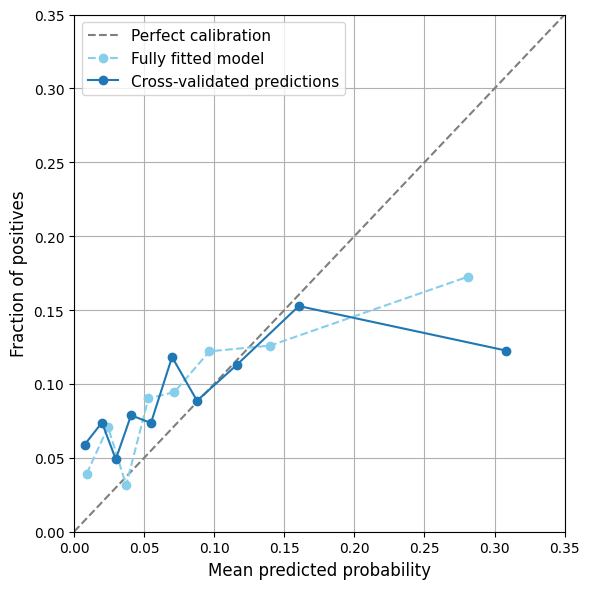

In [19]:
# First curve: from cross-validation
mean_predicted_value_1 = np.array(json.loads(df_crossval_results["mean_predicted_values"][12]))
fraction_of_positives_1 = np.array(json.loads(df_crossval_results["fraction_of_positives"][12]))

# Second curve: from fitted model
y_true = df_pred['positivetest']
y_prob = df_pred['predicted_infections']
fraction_of_positives_2, mean_predicted_value_2 = calibration_curve(y_true, y_prob, n_bins=8, strategy="quantile")

# Plot both on the same figure
plt.figure(figsize=(6, 6))
# Reference line for perfect calibration
plt.plot([0, 1], [0, 1], "--", color="tab:gray", label="Perfect calibration")
plt.plot(mean_predicted_value_2, fraction_of_positives_2, "o--", color="skyblue",
         label="Fully fitted model")
plt.plot(mean_predicted_value_1, fraction_of_positives_1, "o-", color="tab:blue",
         label="Cross-validated predictions")

# Labels and limits
plt.xlabel("Mean predicted probability", size=12)
plt.ylabel("Fraction of positives", size=12)
#plt.title("Calibration curve of selected model", size=16)
plt.xlim(0, 0.35)
plt.ylim(0, 0.35)
plt.legend(fontsize=11)
plt.grid(True)
plt.tight_layout()
plt.savefig("results/cc_selected_model.png", bbox_inches='tight')
plt.show()

Plot the predicted positive tests and the partitioning between causes

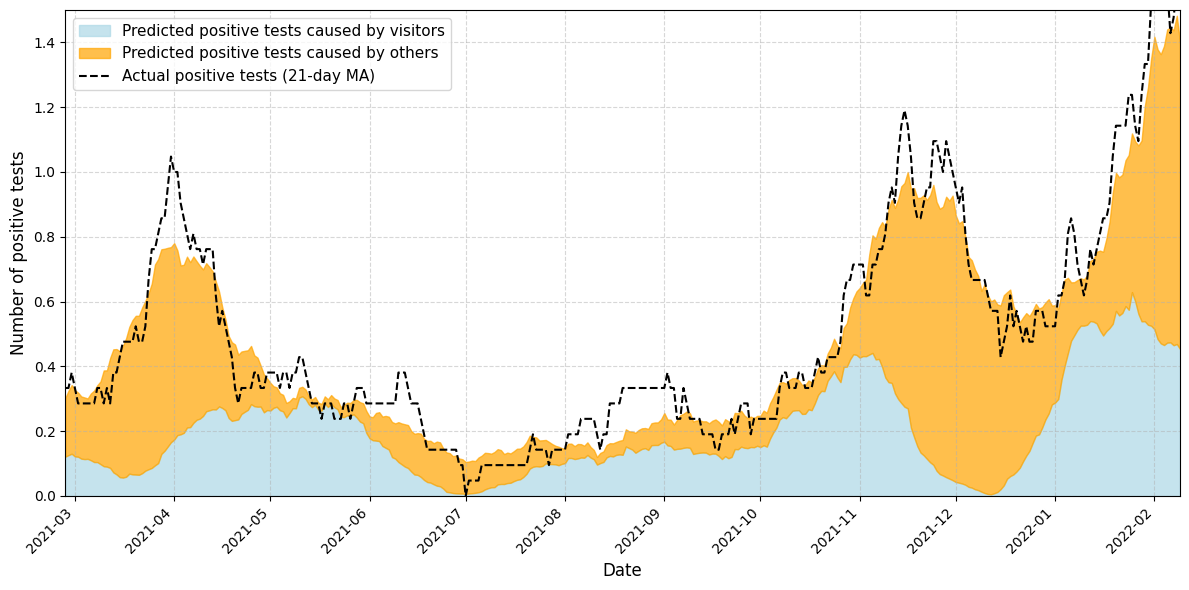

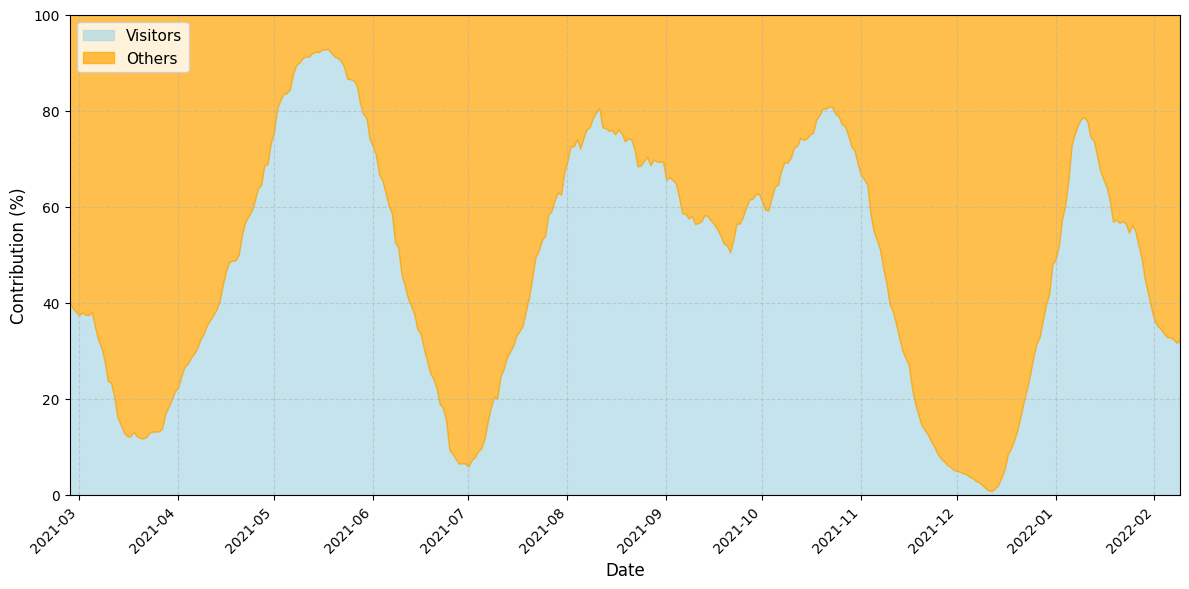

In [6]:
plot_cause_split(df_pred, window_size=21, save_path="results/predicted_infections_by_cause.png", show_title=False)
plot_cause_split_proportions(df_pred, window_size=21, save_path="results/causes_split_proportions.png", show_title=False)

Plot the median sum of contacts within each estimation window

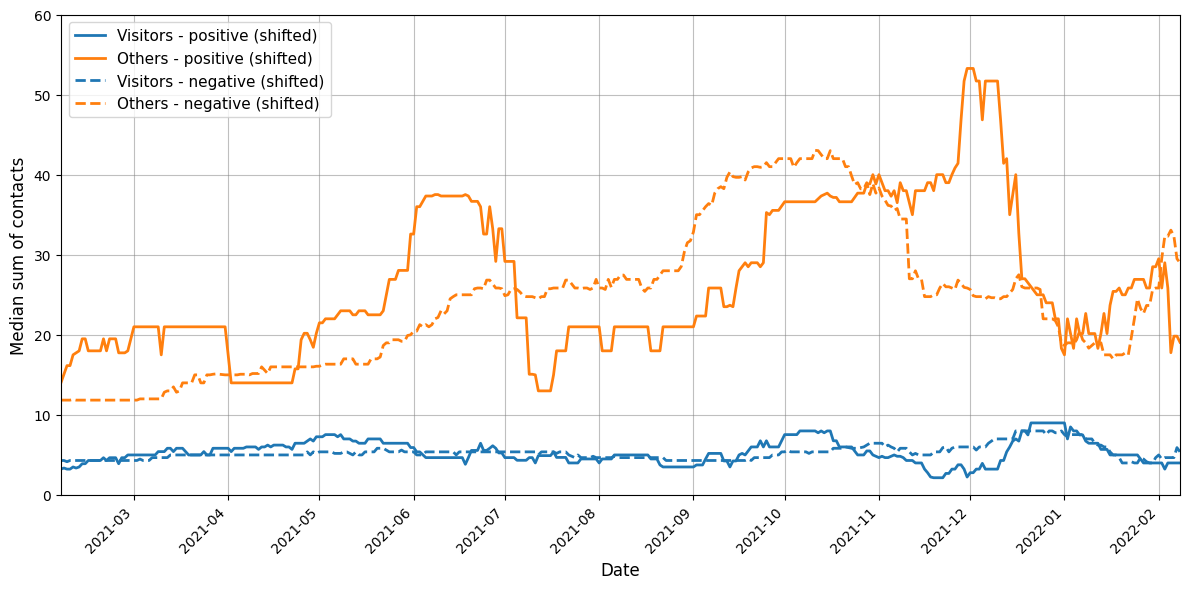

In [34]:
# Ensure datetime format
df_max2['T0_date'] = pd.to_datetime(df_max2['T0_date'])
df_risk['T0_date'] = pd.to_datetime(df_risk['T0_date'])

# Filter only where full_window_used is True
df_risk_filtered = df_risk[df_risk['full_window_used'] == True].copy()

# Shift T0 dates for alignment
df_risk_filtered['shifted_T0_date'] = df_risk_filtered['T0_date'] - pd.to_timedelta(11, unit='D')

show_window_shading = False
if show_window_shading:
    norm = mcolors.Normalize(vmin=df_risk_filtered['window_size_days'].min(),
                             vmax=df_risk_filtered['window_size_days'].max())
    viridis = plt.colormaps['gist_gray']
    viridis_with_alpha = viridis(np.linspace(0, 1, 256))
    viridis_with_alpha[:, -1] = 0.4  # Set alpha
    cmap_with_alpha = ListedColormap(viridis_with_alpha)

# Collect median values per window
records = []
for _, row in df_risk_filtered.iterrows():
    t0 = row['T0_date']
    half_window = pd.Timedelta(days=row['window_size_days'] / 2)
    start = t0 - half_window
    end = t0 + half_window

    df_window = df_max2[(df_max2['T0_date'] >= start) & (df_max2['T0_date'] <= end)]

    df_pos = df_window[df_window['positivetest'] == 1]
    df_neg = df_window[df_window['positivetest'] == 0]

    records.append({
        'shifted_T0_date': row['shifted_T0_date'],  # Shifted date used for plotting
        'visitors_pos': df_pos['sum_visitors_t1_t11_interpolated'].median(),
        'others_pos': df_pos['sum_others_t1_t11_interpolated'].median(),
        'visitors_neg': df_neg['sum_visitors_t1_t11_interpolated'].median(),
        'others_neg': df_neg['sum_others_t1_t11_interpolated'].median()
    })

# Create DataFrame
df_window_medians = pd.DataFrame(records)

# === Plot ===
fig, ax = plt.subplots(figsize=(12, 6))

if show_window_shading:
    for _, row in df_risk_filtered.iterrows():
        ax.axvspan(
            row['shifted_T0_date'],
            row['shifted_T0_date'] + pd.Timedelta(days=1),
            color=cmap_with_alpha(norm(row['window_size_days'])),
            linewidth=0
        )

# Plot median contact values
ax.plot(df_window_medians['shifted_T0_date'], df_window_medians['visitors_pos'],
        label='Visitors - positive (shifted)', color='tab:blue', linewidth=2)
ax.plot(df_window_medians['shifted_T0_date'], df_window_medians['others_pos'],
        label='Others - positive (shifted)', color='tab:orange', linewidth=2)
ax.plot(df_window_medians['shifted_T0_date'], df_window_medians['visitors_neg'],
        label='Visitors - negative (shifted)', color='tab:blue', linestyle='--', linewidth=2)
ax.plot(df_window_medians['shifted_T0_date'], df_window_medians['others_neg'],
        label='Others - negative (shifted)', color='tab:orange', linestyle='--', linewidth=2)

# Axis formatting
ax.set_xlim(df_window_medians['shifted_T0_date'].min(), df_window_medians['shifted_T0_date'].max())
ax.set_ylim(0, 60)
ax.xaxis.set_major_locator(mdates.MonthLocator())
#ax.set_title('Median sum of contacts within each estimation window', size=16)
ax.set_xlabel('Date', size=12)
ax.set_ylabel('Median sum of contacts', size=12)
ax.legend(loc="upper left", fontsize=11)
ax.grid(True, c="gray", alpha=0.5)
plt.xticks(rotation=45, ha='right')

if show_window_shading:
    sm = ScalarMappable(cmap=cmap_with_alpha, norm=norm)
    sm.set_array(df_risk_filtered['window_size_days'])
    cbar = plt.colorbar(sm, ax=ax, pad=0.02)
    cbar.set_label('Window size (days)', size=12)

plt.tight_layout()
plt.savefig("results/median_contacts_by_window.png", dpi=200, bbox_inches='tight')
plt.show()

## Estimates and confidence intervals for estimated risk per contact



In [ ]:
test_output = bootstrap_confidence_intervals_pred(df_max2, 25, 63, n_bootstraps = 100)
df_ci = test_output[0]
df_ci_pred = test_output[1]
df_ci.to_csv("data/ci_100_20.csv",index = False)
df_ci_pred.to_csv("data/ci_100_pred.csv",index = False)

2195it [00:01, 2166.30it/s]
2195it [00:01, 2051.42it/s]         | 0/100 [00:00<?, ?it/s]
2195it [00:01, 1993.40it/s]         | 1/100 [00:12<20:06, 12.19s/it]
2195it [00:01, 1794.01it/s]         | 2/100 [00:24<20:00, 12.25s/it]
2195it [00:01, 2012.01it/s]         | 3/100 [00:37<20:24, 12.63s/it]
2195it [00:01, 2028.24it/s]         | 4/100 [00:50<20:12, 12.63s/it]
2195it [00:01, 1559.85it/s]         | 5/100 [01:02<19:50, 12.53s/it]
2195it [00:01, 2012.63it/s]         | 6/100 [01:16<20:12, 12.90s/it]
2195it [00:01, 1881.83it/s]         | 7/100 [01:29<20:17, 13.09s/it]
2195it [00:01, 1969.89it/s]         | 8/100 [01:42<20:08, 13.14s/it]
2195it [00:01, 1828.54it/s]         | 9/100 [01:55<19:48, 13.06s/it]
2195it [00:01, 1851.04it/s]         | 10/100 [02:09<19:46, 13.18s/it]
2195it [00:01, 1905.68it/s]         | 11/100 [02:22<19:24, 13.08s/it]
2195it [00:01, 1625.62it/s]▏        | 12/100 [02:35<19:15, 13.13s/it]
2195it [00:01, 1693.95it/s]▎        | 13/100 [02:49<19:27, 13.43s/it]
2195it [00

{'epsilon_lower': 0      1.000000e-10
1      1.000000e-10
2      1.000000e-10
3      1.000000e-10
4      1.000000e-10
           ...     
405    4.696732e-02
406    3.232812e-02
407    1.000000e-10
408    1.000000e-10
409    1.000000e-10
Name: 0.025, Length: 410, dtype: float64, 'epsilon_upper': 0      1.000000e-10
1      1.610061e-02
2      1.322603e-02
3      1.188162e-02
4      8.345348e-03
           ...     
405    8.005087e-02
406    6.632310e-02
407    2.814330e-02
408    1.786631e-02
409    1.000000e-10
Name: 0.975, Length: 410, dtype: float64, 'gamma_lower': 0      1.000000e-10
1      1.000000e-10
2      1.000000e-10
3      1.000000e-10
4      1.000000e-10
           ...     
405    5.018078e-03
406    3.635640e-03
407    1.139809e-02
408    7.938969e-03
409    1.000000e-10
Name: 0.025, Length: 410, dtype: float64, 'gamma_upper': 0      1.000000e-10
1      6.325285e-03
2      4.026527e-03
3      3.451301e-03
4      2.039772e-03
           ...     
405    1.281142e-02
406    1.

In [7]:
df_ci = pd.read_csv("data/ci_100.csv")
df_ci['T0_date'] = pd.to_datetime(df_ci['T0_date'])

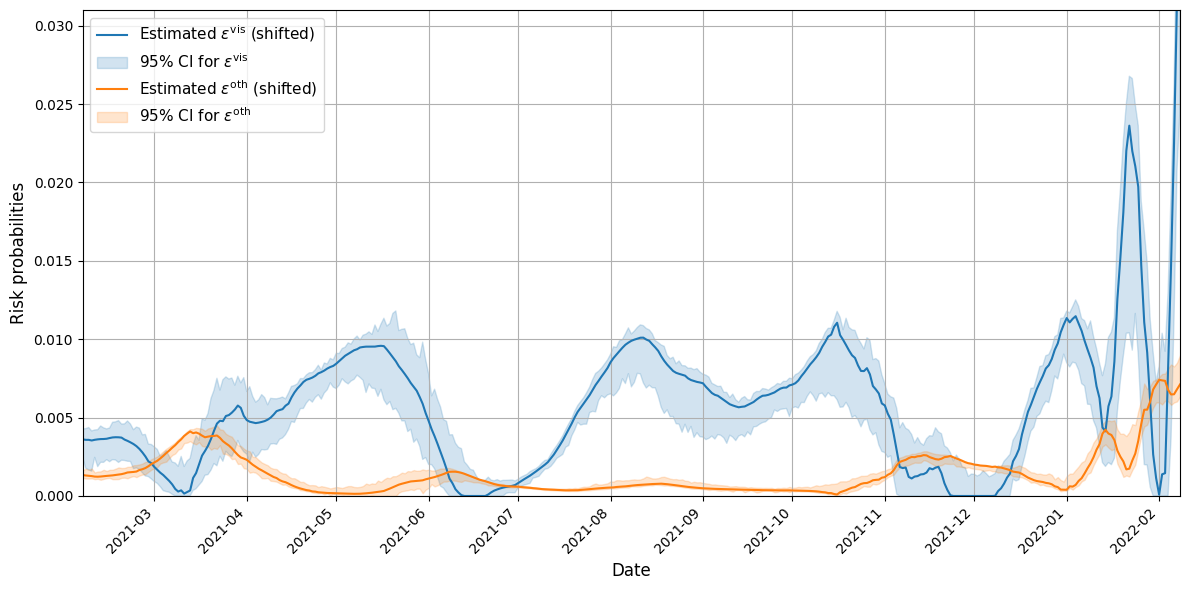

In [8]:
# Only use rows where full window was used
df_plot = df_ci[df_ci["full_window_used"] == 1].copy()

# Shift T0 dates for x-axis
df_plot["shifted_T0_date"] = df_plot["T0_date"] - pd.to_timedelta(11, unit='D')

# Only plot the dates where the full window was used
df_risk_clean = df_risk[df_risk['full_window_used'] == 1].copy()

# Shift T0 dates by 11 days earlier
df_risk_clean['shifted_T0_date'] = df_risk_clean['T0_date'] - pd.to_timedelta(11, unit='D')


show_window_shading = False
if show_window_shading:
    norm = mcolors.Normalize(vmin=df_risk_clean['window_size_days'].min(),
                             vmax=df_risk_clean['window_size_days'].max())

    # Create transparent version of viridis colormap
    alpha = 0.4
    viridis = plt.colormaps['gist_gray']
    viridis_with_alpha = viridis(np.linspace(0, 1, 256))
    viridis_with_alpha[:, -1] = alpha  # Set alpha in RGBA
    cmap_with_alpha = ListedColormap(viridis_with_alpha)

plt.figure(figsize=(12, 6))

if show_window_shading:
    for _, row in df_risk_clean.iterrows():
        plt.axvspan(
            row['shifted_T0_date'],
            row['shifted_T0_date'] + pd.Timedelta(days=1),  # one-day span
            color=cmap_with_alpha(norm(row['window_size_days'])),
            linewidth=0
        )

# === Epsilon ===
plt.plot(df_plot["shifted_T0_date"], df_plot["estimated_epsilon"], label=r'Estimated $\epsilon^{\mathrm{vis}}$ (shifted)', color="tab:blue")
plt.fill_between(df_plot["shifted_T0_date"], df_plot["epsilon_lower"], df_plot["epsilon_upper"],
                 color="tab:blue", alpha=0.2, label=r"95% CI for $\epsilon^{\mathrm{vis}}$")

# === Gamma ===
plt.plot(df_plot["shifted_T0_date"], df_plot["estimated_gamma"], label=r'Estimated $\epsilon^{\mathrm{oth}}$ (shifted)', color="tab:orange")
plt.fill_between(df_plot["shifted_T0_date"], df_plot["gamma_lower"], df_plot["gamma_upper"],
                 color="tab:orange", alpha=0.2, label=r"95% CI for $\epsilon^{\mathrm{oth}}$")


# Formatting
plt.xlim(df_plot["shifted_T0_date"].min(), df_plot["shifted_T0_date"].max())
plt.ylim(0, 0.031)

ax = plt.gca()
ax.xaxis.set_major_locator(mdates.MonthLocator())
plt.xticks(rotation=45, ha='right')

if show_window_shading:
    sm = ScalarMappable(cmap=cmap_with_alpha, norm=norm)
    sm.set_array(df_risk_clean['window_size_days'])
    cbar = plt.colorbar(sm, ax=ax, pad=0.02)
    cbar.set_label('Window size (days)', size=12)

#plt.title("Estimated risk per contact over time", fontsize=16)
plt.xlabel("Date", fontsize=12)
plt.ylabel("Risk probabilities", fontsize=12)
plt.legend(loc="upper left", fontsize=11)
plt.grid(True)
plt.tight_layout()
plt.savefig("results/per_contact_risk.png", dpi=200, bbox_inches='tight')
plt.show()

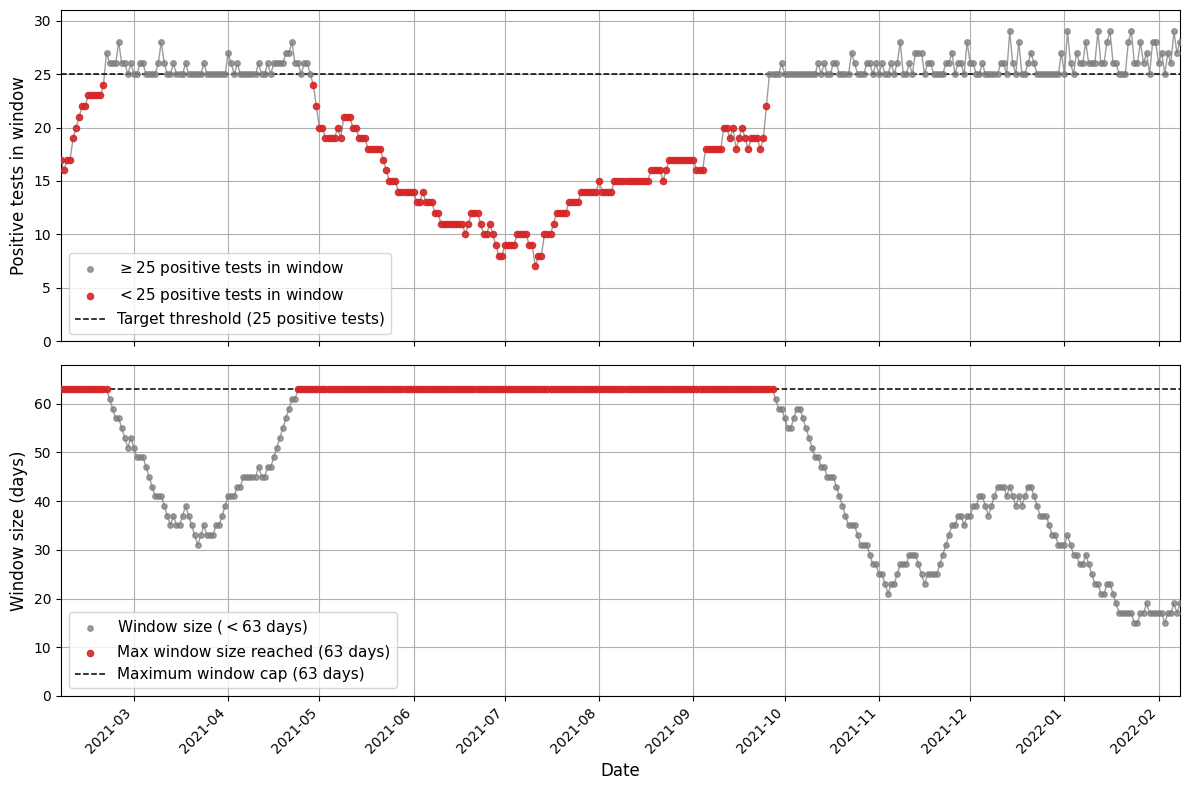

In [33]:
max_cap = 63
target_pos = 25
pos_col = "pos_tests_in_window"

df_all = df_risk[df_risk["full_window_used"] == 1].copy()
df_all["shifted_T0_date"] = pd.to_datetime(df_all["T0_date"]) - pd.to_timedelta(
    11, unit="D"
)
df_all = df_all.sort_values("shifted_T0_date")

below_target = df_all[pos_col] < target_pos
df_below = df_all[below_target]
df_at_or_above = df_all[~below_target]

is_capped = df_all["window_size_days"] >= max_cap
df_uncapped = df_all[~is_capped]
df_capped = df_all[is_capped]

fig, (ax_pos, ax_win) = plt.subplots(
    2, 1, figsize=(12, 8), sharex=True, gridspec_kw={"height_ratios": [1, 1]}
)

# --- Top panel: Positive tests in window ---
ax_pos.plot(
    df_all["shifted_T0_date"],
    df_all[pos_col],
    color="0.45",
    linewidth=1.0,
    alpha=0.7,
    zorder=2,
)
ax_pos.scatter(
    df_at_or_above["shifted_T0_date"],
    df_at_or_above[pos_col],
    s=16,
    color="tab:gray",
    alpha=0.75,
    label=rf"$\geq {target_pos}$ positive tests in window",
    zorder=3,
)
ax_pos.scatter(
    df_below["shifted_T0_date"],
    df_below[pos_col],
    s=20,
    color="tab:red",
    alpha=0.9,
    label=rf"$< {target_pos}$ positive tests in window",
    zorder=4,
)
ax_pos.axhline(
    target_pos,
    color="black",
    linestyle="--",
    linewidth=1.1,
    label=f"Target threshold ({target_pos} positive tests)",
    zorder=2,
)
y_pos_max = max(22, int(df_all[pos_col].max()) + 2) if not df_all.empty else 22
ax_pos.set_ylim(0, y_pos_max)
ax_pos.set_ylabel("Positive tests in window", fontsize=12)
ax_pos.grid(True, zorder=0)
ax_pos.legend(loc="lower left", fontsize=11)

# --- Bottom panel: Window size ---
ax_win.plot(
    df_all["shifted_T0_date"],
    df_all["window_size_days"],
    color="0.45",
    linewidth=1.0,
    alpha=0.7,
    zorder=2,
)
ax_win.scatter(
    df_uncapped["shifted_T0_date"],
    df_uncapped["window_size_days"],
    s=15,
    color="tab:gray",
    alpha=0.75,
    label=rf"Window size ($< {max_cap}$ days)",
    zorder=3,
)
ax_win.scatter(
    df_capped["shifted_T0_date"],
    df_capped["window_size_days"],
    s=20,
    color="tab:red",
    alpha=0.9,
    label=f"Max window size reached ({max_cap} days)",
    zorder=4,
)
ax_win.axhline(
    max_cap,
    color="black",
    linestyle="--",
    linewidth=1.1,
    label=f"Maximum window cap ({max_cap} days)",
    zorder=2,
)
ax_win.set_ylim(0, max_cap + 5)
ax_win.set_ylabel("Window size (days)", fontsize=12)
ax_win.grid(True, zorder=0)
ax_win.legend(loc="lower left", fontsize=11)

# Shared x-axis formatting
if "df_plot" in locals() and not df_plot.empty:
  x_min, x_max = df_plot["shifted_T0_date"].min(), df_plot["shifted_T0_date"].max()
else:
  x_min, x_max = df_all["shifted_T0_date"].min(), df_all["shifted_T0_date"].max()

ax_win.set_xlim(x_min, x_max)
ax_win.xaxis.set_major_locator(mdates.MonthLocator())
ax_win.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
plt.setp(ax_win.get_xticklabels(), rotation=45, ha="right")
ax_win.set_xlabel("Date", fontsize=12)

# fig.suptitle(
#     "Positive tests and window size per estimation window over time",
#     fontsize=16,
# )
plt.tight_layout()
plt.savefig("results/window_size_and_positives.png", dpi=200, bbox_inches="tight")
plt.show()

In [10]:
df_ci_pred = pd.read_csv('data/ci_100_pred.csv')

df_ci_predict = df_ci_pred.copy()
df_ci_predict['T0_date'] = pd.to_datetime(df_ci_predict['T0_date'])

Correlation is 0.9755546520020901


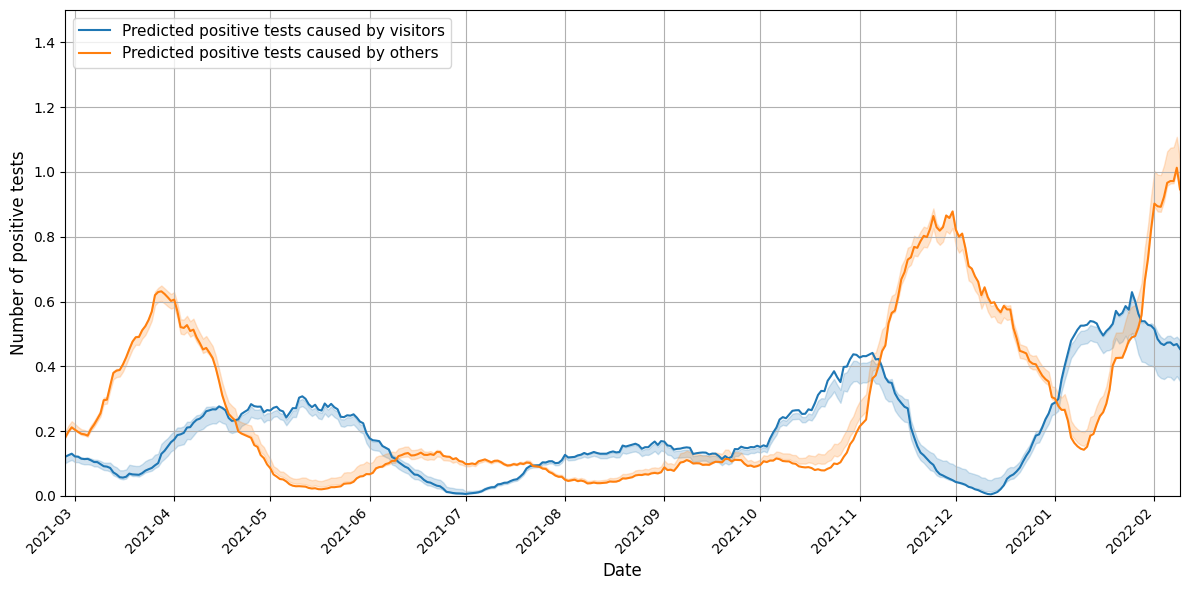

In [11]:
smoothed_predictions_plot_CI(df_ci_predict, 21, save_path="results/predicted_infections_by_cause_CI.png", show_title=False)

## Grid search to determine hyperparameters for simplified model

(threshold for the maximum number of missing surveys during the baseline period and the size of the sliding window)

In [13]:
results = []

# Add the datasets to the dictionary
datasets = {
    #"df_max0": df_max0,
    #"df_max1": df_max1,
    #"df_max2": df_max2,
    #"df_max3": df_max3,
    "df_max4": df_max4
}

# Define the window sizes you want to evaluate
window_sizes = [15, 20, 25, 30, 35]

# Run cross-validation for each combination
for name, df in datasets.items():
    for window_size in window_sizes:
        print(f"\nRunning for dataset: {name}, min_total_tests: {window_size}")
        
        nr_predictions, actuals, predictions, ace, brier, frac_pos, mean_pred, actual_bins, window_sizes_used, max_window_used, pos_tests_used = cross_validation_adaptive_window_simple(df.copy(), window_size, max_window_size_days=63)
        
        results.append({
            "dataset": name,
            "window_size": window_size,
            "ACE": ace,
            "BrierScore": brier,
            "n_samples": len(actuals),
            "fraction_of_positives": json.dumps(frac_pos.tolist()),
            "mean_predicted_values": json.dumps(mean_pred.tolist()),
            "n_predictions": nr_predictions,
            "n_bins": actual_bins,
            "predictions": json.dumps(predictions.tolist()),
            "actuals": json.dumps(actuals.tolist()),
            "window_sizes": json.dumps(window_sizes_used.tolist()),
            "max_window_used": json.dumps(max_window_used.tolist()),
            "pos_tests_used": json.dumps(pos_tests_used.tolist())
        })

# Convert results to DataFrame
results_df = pd.DataFrame(results)
results_df.to_csv("crossval_data/crossval_summary_adaptive_pos_simple_4_x_63_new.csv", index=False)


Running for dataset: df_max4, min_total_tests: 15
Processing Fold 1
Processing Fold 2
Processing Fold 3
Processing Fold 4
Processing Fold 5
Processing Fold 6
Processing Fold 7
Processing Fold 8
Processing Fold 9
Processing Fold 10

Running for dataset: df_max4, min_total_tests: 20
Processing Fold 1
Processing Fold 2
Processing Fold 3
Processing Fold 4
Processing Fold 5
Processing Fold 6
Processing Fold 7
Processing Fold 8
Processing Fold 9
Processing Fold 10

Running for dataset: df_max4, min_total_tests: 25
Processing Fold 1
Processing Fold 2
Processing Fold 3
Processing Fold 4
Processing Fold 5
Processing Fold 6
Processing Fold 7
Processing Fold 8
Processing Fold 9
Processing Fold 10

Running for dataset: df_max4, min_total_tests: 30
Processing Fold 1
Processing Fold 2
Processing Fold 3
Processing Fold 4
Processing Fold 5
Processing Fold 6
Processing Fold 7
Processing Fold 8
Processing Fold 9
Processing Fold 10

Running for dataset: df_max4, min_total_tests: 35
Processing Fold 1
Pro

In [14]:
df_0 = pd.read_csv("crossval_data/crossval_summary_adaptive_pos_simple_0_x_63.csv")
df_1 = pd.read_csv("crossval_data/crossval_summary_adaptive_pos_simple_1_x_63.csv")
df_2 = pd.read_csv("crossval_data/crossval_summary_adaptive_pos_simple_2_x_63.csv")
df_3 = pd.read_csv("crossval_data/crossval_summary_adaptive_pos_simple_3_x_63.csv")
df_4 = pd.read_csv("crossval_data/crossval_summary_adaptive_pos_simple_4_x_63.csv")

df_crossval_results_simple = pd.concat([df_0, df_1, df_2, df_3, df_4], ignore_index=True)
# Convert string to list in each row
df_crossval_results_simple["window_sizes"] = df_crossval_results_simple["window_sizes"].apply(ast.literal_eval)

# Compute average window size per row
df_crossval_results_simple["avg_window_size"] = df_crossval_results_simple["window_sizes"].apply(lambda x: sum(x) / len(x))

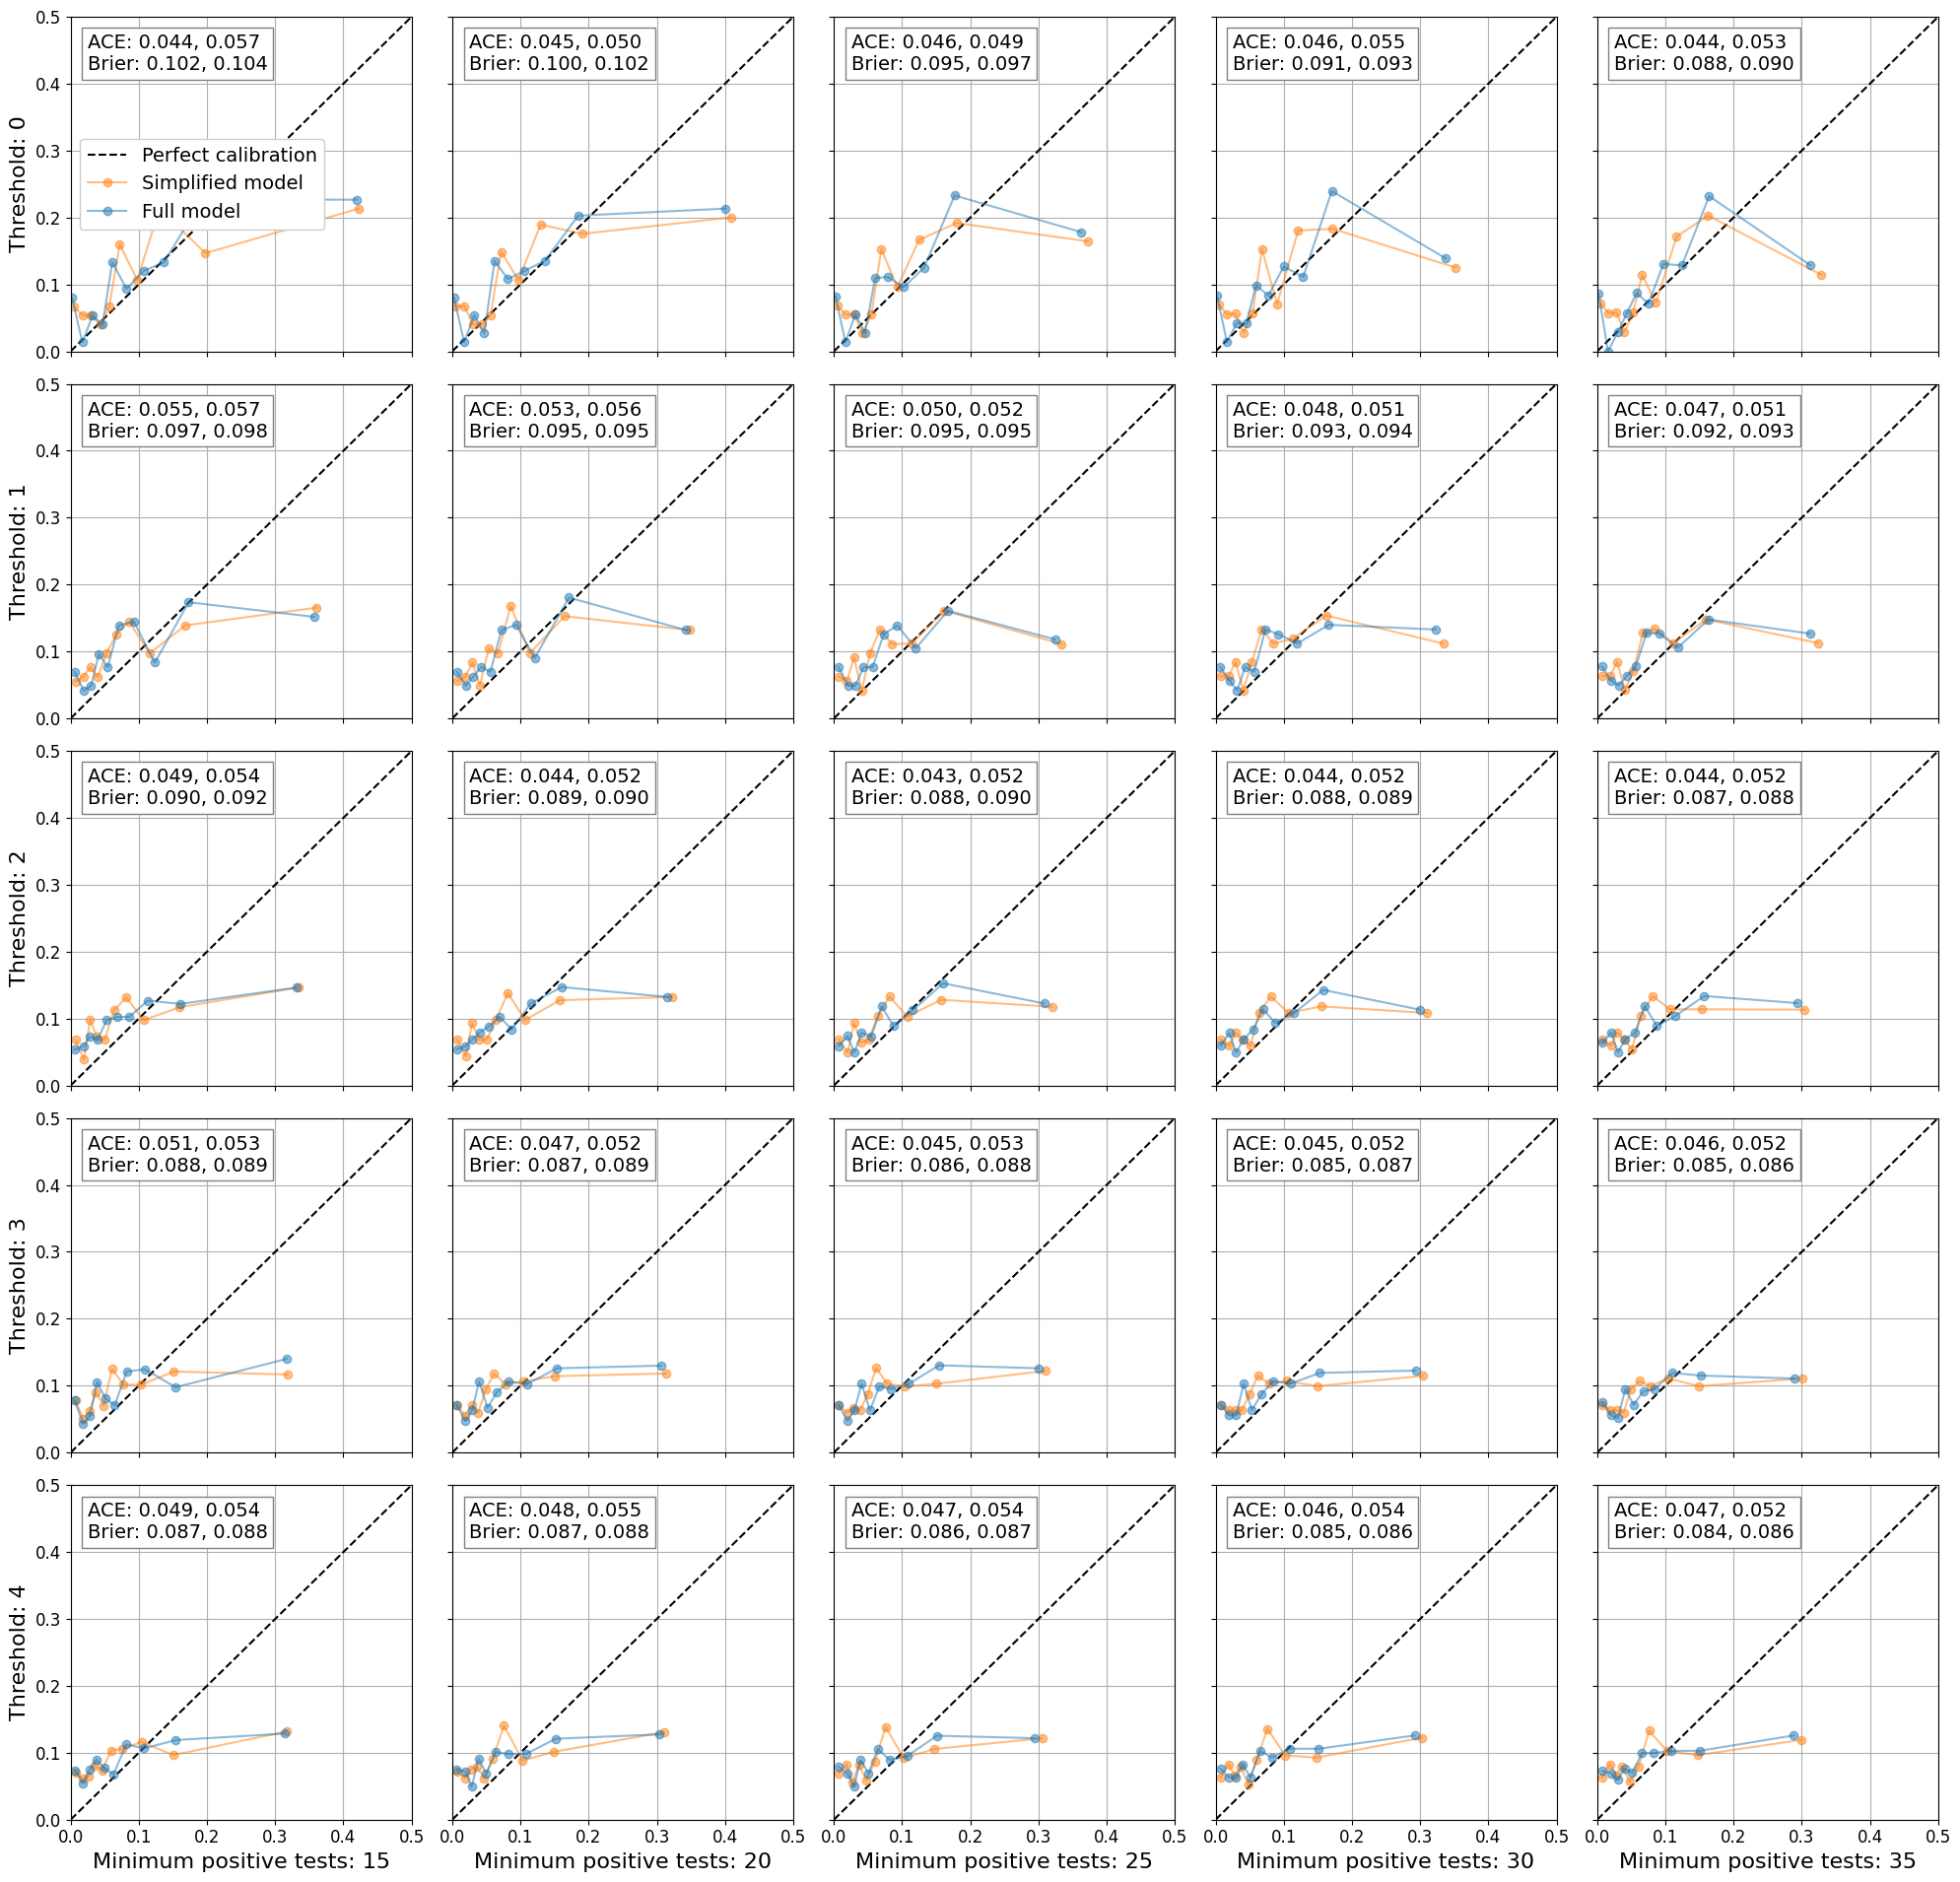

In [15]:
datasets = sorted(df_crossval_results_simple["dataset"].unique())
window_sizes = sorted(df_crossval_results_simple["window_size"].unique())

n_rows = len(datasets)
n_cols = len(window_sizes)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 4 * n_rows), sharex=True, sharey=True)

for i, dataset in enumerate(datasets):
    for j, window_size in enumerate(window_sizes):
        ax = axes[i, j] if n_rows > 1 else axes[j]

        # Filter rows for both models
        row_orig = df_crossval_results[(df_crossval_results["dataset"] == dataset) & 
                                       (df_crossval_results["window_size"] == window_size)]
        row_simple = df_crossval_results_simple[(df_crossval_results_simple["dataset"] == dataset) & 
                                (df_crossval_results_simple["window_size"] == window_size)]

        # If neither model has data, hide the axes
        if row_orig.empty and row_simple.empty:
            ax.axis('off')
            continue

        # Reference line
        ax.plot([0, 1], [0, 1], "k--", label="Perfect calibration")
        
        

        # Plot simplified model (orange)
        if not row_simple.empty:
            mean_pred_simple = np.array(json.loads(row_simple.iloc[0]["mean_predicted_values"]))
            frac_pos_simple = np.array(json.loads(row_simple.iloc[0]["fraction_of_positives"]))
            ace_simple = row_simple.iloc[0]["ACE"]
            brier_simple = row_simple.iloc[0]["BrierScore"]
            ax.plot(mean_pred_simple, frac_pos_simple, "o-", color="tab:orange", label="Simplified model", alpha=0.5)

        # Plot original model (blue)
        if not row_orig.empty:
            mean_pred_orig = np.array(json.loads(row_orig.iloc[0]["mean_predicted_values"]))
            frac_pos_orig = np.array(json.loads(row_orig.iloc[0]["fraction_of_positives"]))
            ace_orig = row_orig.iloc[0]["ACE"]
            brier_orig = row_orig.iloc[0]["BrierScore"]
            ax.plot(mean_pred_orig, frac_pos_orig, "o-", color="tab:blue", label="Full model", alpha=0.5)        

        #Add annotations showing metrics for both models
        annotation_text = (
            f"ACE: {ace_orig:.3f}, {ace_simple:.3f}\n"
            f"Brier: {brier_orig:.3f}, {brier_simple:.3f}"
        )

        ax.text(0.05, 0.95, annotation_text,
                transform=ax.transAxes, fontsize=14,
                verticalalignment='top', bbox=dict(facecolor='white', alpha=1, edgecolor='gray'))
        
        if i == n_rows - 1:
            ax.set_xlabel(f"Minimum positive tests: {window_size}", fontsize=16)
        if j == 0:
            ax.set_ylabel(f"Threshold: {dataset[-1]}", fontsize=16)

        ax.set_xlim(0, 0.5)
        ax.set_ylim(0, 0.5)
        ax.tick_params(axis='both', labelsize=12)
        ax.grid(True)

        # Only show legend on the first subplot
        if i == 0 and j == 0:
            ax.legend(loc="center left", fontsize=14, framealpha=1)

#plt.suptitle("Calibration curves of full and simplified models", fontsize=32)
plt.tight_layout(rect=[0, 0.03, 1, 0.99])
plt.savefig("results/calibration_grid_combined.png", dpi=200, bbox_inches='tight')
plt.show()

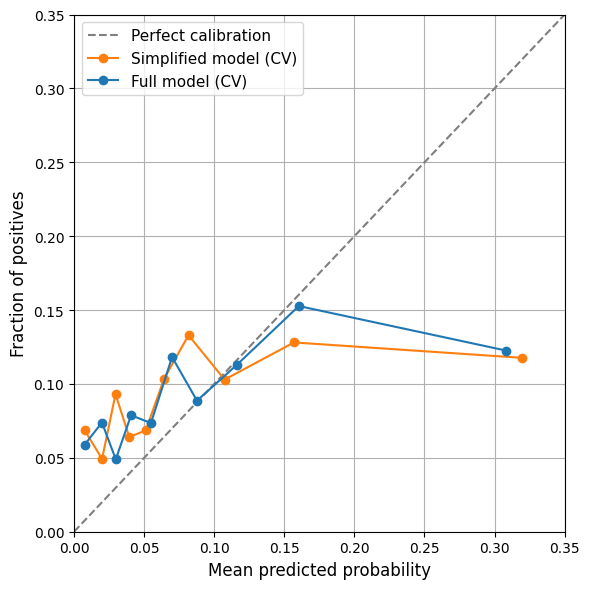

In [35]:
# Filter the data
row_orig = df_crossval_results[
    (df_crossval_results["dataset"].str.endswith("2")) & 
    (df_crossval_results["window_size"] == 25)
]

row_simple = df_crossval_results_simple[
    (df_crossval_results_simple["dataset"].str.endswith("2")) & 
    (df_crossval_results_simple["window_size"] == 25)
]

plt.figure(figsize=(6, 6))

# Reference line for perfect calibration
plt.plot([0, 1], [0, 1], "--", color="tab:gray", label="Perfect calibration")

# Plot simplified model
if not row_simple.empty:
    mean_pred_simple = np.array(json.loads(row_simple.iloc[0]["mean_predicted_values"]))
    frac_pos_simple = np.array(json.loads(row_simple.iloc[0]["fraction_of_positives"]))
    plt.plot(mean_pred_simple, frac_pos_simple, "o-", color="tab:orange", 
             label="Simplified model (CV)")

# Plot original model
if not row_orig.empty:
    mean_pred_orig = np.array(json.loads(row_orig.iloc[0]["mean_predicted_values"]))
    frac_pos_orig = np.array(json.loads(row_orig.iloc[0]["fraction_of_positives"]))
    plt.plot(mean_pred_orig, frac_pos_orig, "o-", color="tab:blue", 
             label="Full model (CV)")

# Labels, limits, and styling
plt.xlabel("Mean predicted probability", size=12)
plt.ylabel("Fraction of positives", size=12)
#plt.title("Comparison of calibration curves", size=16)
plt.xlim(0, 0.35)
plt.ylim(0, 0.35)
plt.legend(fontsize=11)
plt.grid(True)
plt.tight_layout()
plt.savefig("results/simple_vs_full_calibration_curves.png", bbox_inches='tight')
plt.show()